# Exercise 6.4 - MNIST classification

I split the official training data into 54,000 training and 6,000 validation images and kept the 10,000 official test images for evaluation. I flattened each image, scaled its pixels to [0, 1], and encoded labels as ten classes. All models in this report trained for ten epochs on the same full training split. I chose configurations by validation accuracy.

## Results from the completed Colab run

The 128-unit baseline reached 97.77% test accuracy. Increasing the width to 256 gave 97.85%, while using two layers with 128 and 64 units gave 97.74%. The small differences in this run do not establish a consistent advantage for either change.

The best grid configuration used 256 units and zero dropout (95.10% validation and 95.68% test). The random search winner used 256 units, ReLU, 0.1 dropout, a learning rate of 0.001 and batches of 64 (97.52% validation and 98.03% test, with validation cross entropy 0.0875). The grid fixed the learning rate at 0.0001, so the two searches explored different settings.

The budget plot repeats sampling at each budget 50 times from the same 20 completed trials. The mean of the best observed validation losses describes this candidate pool. The shaded band is one standard deviation across sampled subsets. It does not estimate variability across independent training runs.

In [1]:
from itertools import product
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras


In [2]:
# Prepare the images and labels.
SEED = 640
keras.utils.set_random_seed(SEED)
(x_all, y_all), (x_test_images, y_test) = keras.datasets.mnist.load_data()
order = np.random.default_rng(SEED).permutation(len(y_all))
train, val = order[6000:], order[:6000]

def flatten(images):
    return images.reshape(-1, 784).astype('float32') / 255.0

x_train = flatten(x_all[train])
x_val = flatten(x_all[val])
x_test = flatten(x_test_images)
y_train = keras.utils.to_categorical(y_all[train], 10)
y_val = keras.utils.to_categorical(y_all[val], 10)
y_test_hot = keras.utils.to_categorical(y_test, 10)
print('Train, validation, test:', len(x_train), len(x_val), len(x_test))


Train, validation, test: 54000 6000 10000


In [3]:
# Define and train a network.
def fit_model(widths, dropout, rate=0.001, batch=128, activation='relu',
              seed=SEED, evaluate_test=True):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    # Add the hidden layers in the same order as the chosen widths.
    network_layers = [keras.Input(shape=(784,))]
    for layer_number, width in enumerate(widths):
        network_layers.append(keras.layers.Dense(width, activation=activation))
        if layer_number == 0:
            network_layers.append(keras.layers.Dropout(dropout))
    network_layers.append(keras.layers.Dense(10, activation='softmax'))
    model = keras.Sequential(network_layers)
    model.compile(optimizer=keras.optimizers.Adam(rate),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    started = perf_counter()
    print(f'Training {widths}, dropout={dropout}, rate={rate}, batch={batch}', flush=True)
    history = model.fit(x_train, y_train, batch_size=batch, epochs=10,
                        validation_data=(x_val, y_val), verbose=2).history
    accuracy = None
    if evaluate_test:
        _, accuracy = model.evaluate(x_test, y_test_hot, batch_size=512, verbose=0)
    print(f'Finished in {perf_counter() - started:.1f} seconds', flush=True)
    return model, history, accuracy


Baseline test accuracy: 97.77%


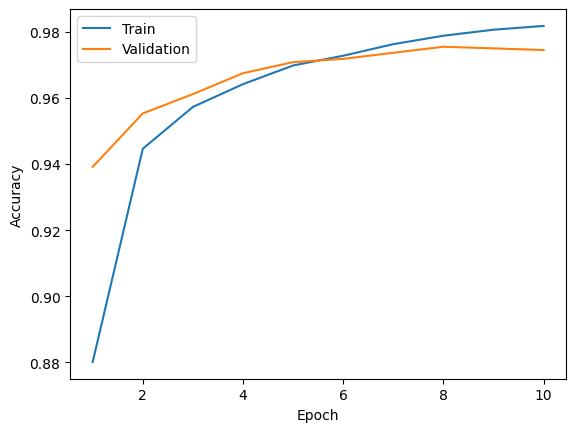

In [4]:
# Train the 128 node network.
baseline, history, baseline_accuracy = fit_model((128,), 0.2)
print(f'Baseline test accuracy: {baseline_accuracy:.2%}')
epochs = np.arange(1, 11)
plt.plot(epochs, history['accuracy'], label='Train')
plt.plot(epochs, history['val_accuracy'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


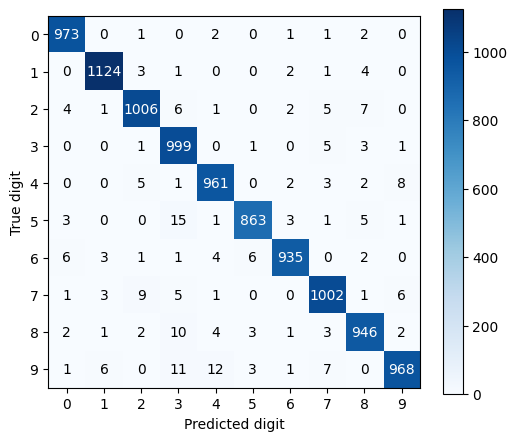

In [5]:
# Check the confusion matrix.
prediction = baseline.predict(x_test, verbose=0).argmax(axis=1)
confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (y_test, prediction), 1)
fig, ax = plt.subplots(figsize=(6, 5))
heatmap = ax.imshow(confusion, cmap='Blues')
ax.set(xlabel='Predicted digit', ylabel='True digit',
       xticks=range(10), yticks=range(10))
for row, col in product(range(10), repeat=2):
    value = confusion[row, col]
    color = 'white' if value > confusion.max() / 2 else 'black'
    ax.text(col, row, str(value), ha='center', va='center', color=color)
fig.colorbar(heatmap, ax=ax)
plt.show()


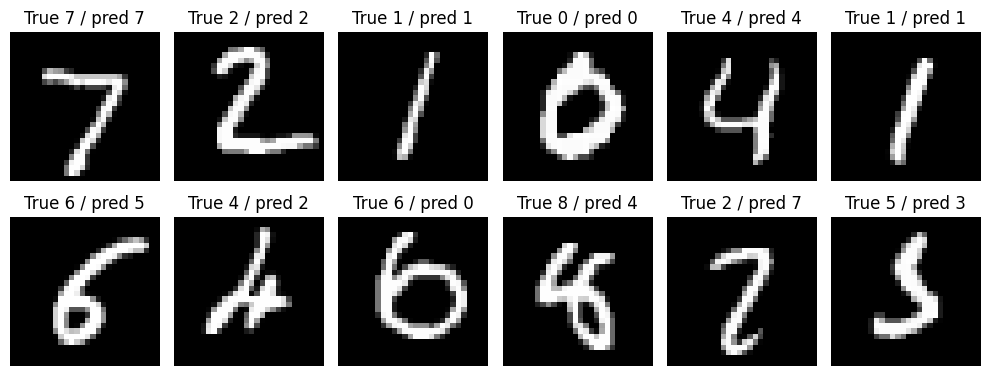

In [6]:
# Show correct and incorrect predictions.
fig, axes = plt.subplots(2, 6, figsize=(10, 4))
for axs, mask in zip(axes, (prediction == y_test, prediction != y_test)):
    for ax, i in zip(axs, np.flatnonzero(mask)[:6]):
        ax.imshow(x_test_images[i], cmap='gray')
        ax.set_title(f'True {y_test[i]} / pred {prediction[i]}')
        ax.axis('off')
fig.tight_layout()
plt.show()


In [7]:
# Compare different hidden layers.
print('Architecture, final validation accuracy, test accuracy')
print((128,), f"{history['val_accuracy'][-1]:.2%}",
      f'{baseline_accuracy:.2%}')
for widths in [(256,), (128, 64)]:
    _, h, test = fit_model(widths, 0.2)
    print(widths, f"{h['val_accuracy'][-1]:.2%}", f'{test:.2%}')


Architecture, final validation accuracy, test accuracy
(128,) 97.45% 97.77%
(256,) 97.92% 97.85%
(128, 64) 97.42% 97.74%


 32 units, dropout 0.0, val 91.80%, test 92.34%
 64 units, dropout 0.0, val 92.93%, test 93.60%
128 units, dropout 0.0, val 94.45%, test 94.58%
256 units, dropout 0.0, val 95.10%, test 95.68%
 32 units, dropout 0.2, val 90.97%, test 91.85%
 64 units, dropout 0.2, val 92.57%, test 93.51%
128 units, dropout 0.2, val 94.20%, test 94.69%
256 units, dropout 0.2, val 95.10%, test 95.74%
 32 units, dropout 0.4, val 90.35%, test 91.32%
 64 units, dropout 0.4, val 92.08%, test 92.95%
128 units, dropout 0.4, val 93.83%, test 94.32%
256 units, dropout 0.4, val 94.95%, test 95.40%
 32 units, dropout 0.6, val 89.32%, test 90.38%
 64 units, dropout 0.6, val 91.02%, test 92.15%
128 units, dropout 0.6, val 93.20%, test 93.73%
256 units, dropout 0.6, val 94.25%, test 95.00%
Grid winner by validation accuracy: (256, 0.0, 0.9509999752044678, 0.9567999839782715)


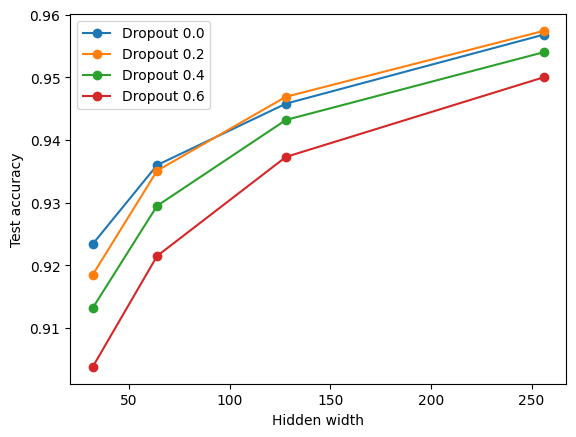

In [8]:
# Grid search over dropout and hidden nodes.
widths = [32, 64, 128, 256]
dropouts = [0.0, 0.2, 0.4, 0.6]
grid = []
for dropout, width in product(dropouts, widths):
    _, h, test = fit_model((width,), dropout, rate=0.0001)
    grid.append((width, dropout, h['val_accuracy'][-1], test))
    print(f'{width:3d} units, dropout {dropout:.1f}, '
          f"val {h['val_accuracy'][-1]:.2%}, test {test:.2%}")
print('Grid winner by validation accuracy:', max(grid, key=lambda row: row[2]))
for dropout in dropouts:
    test_by_width = [test for w, d, val, test in grid if d == dropout]
    plt.plot(widths, test_by_width, marker='o', label=f'Dropout {dropout:.1f}')
plt.xlabel('Hidden width')
plt.ylabel('Test accuracy')
plt.legend()
plt.show()


In [9]:
# Random search over five hyperparameters.
spaces = [
    [8, 32, 128, 256, 512],
    [0, 0.1, 0.2, 0.3, 0.5, 0.6],
    [1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
    [64, 128, 256],
    ['relu', 'elu', 'sigmoid', 'tanh'],
]
candidates = list(product(*spaces))

# Train 20 configurations once, then reuse their measured validation losses.
rng = np.random.default_rng(SEED)
picks = rng.choice(len(candidates), 20, replace=False)
trials = []
for number, ix in enumerate(picks, 1):
    width, dropout, rate, batch, activation = candidates[ix]
    print(f'Random trial {number}/20', flush=True)
    _, h, test = fit_model(
        (width,), dropout, rate=rate, batch=batch, activation=activation,
        seed=SEED + number,
    )
    val_loss = h['val_loss'][-1]
    val_acc = h['val_accuracy'][-1]
    trials.append((candidates[ix], val_loss, val_acc, test))
    print(f'{candidates[ix]} val loss={val_loss:.4f}, '
          f'val accuracy={val_acc:.2%}, test accuracy={test:.2%}')
print('Winner by validation accuracy:', max(trials, key=lambda row: row[2]))
np.save('mnist_random_validation_losses.npy',
        np.array([trial[1] for trial in trials]))


Random trial 1/20
(128, 0.3, 0.01, 64, 'relu') val loss=0.1904, val accuracy=96.08%, test accuracy=96.40%
Random trial 2/20
(512, 0.3, 0.001, 64, 'tanh') val loss=0.0868, val accuracy=97.48%, test accuracy=97.56%
Random trial 3/20
(256, 0.1, 0.01, 128, 'elu') val loss=0.2638, val accuracy=96.80%, test accuracy=97.11%
Random trial 4/20
(512, 0.3, 0.01, 128, 'sigmoid') val loss=0.0992, val accuracy=97.50%, test accuracy=97.81%
Random trial 5/20
(256, 0.1, 0.001, 64, 'relu') val loss=0.0875, val accuracy=97.52%, test accuracy=98.03%
Random trial 6/20
(256, 0.2, 0.0001, 64, 'relu') val loss=0.1425, val accuracy=95.78%, test accuracy=96.45%
Random trial 7/20
(32, 0.1, 0.01, 128, 'sigmoid') val loss=0.1681, val accuracy=95.28%, test accuracy=95.80%
Random trial 8/20
(256, 0.3, 0.1, 64, 'sigmoid') val loss=0.4338, val accuracy=91.15%, test accuracy=91.54%
Random trial 9/20
(512, 0.5, 0.1, 256, 'elu') val loss=1.9039, val accuracy=91.12%, test accuracy=91.94%
Random trial 10/20
(8, 0.5, 0.0001

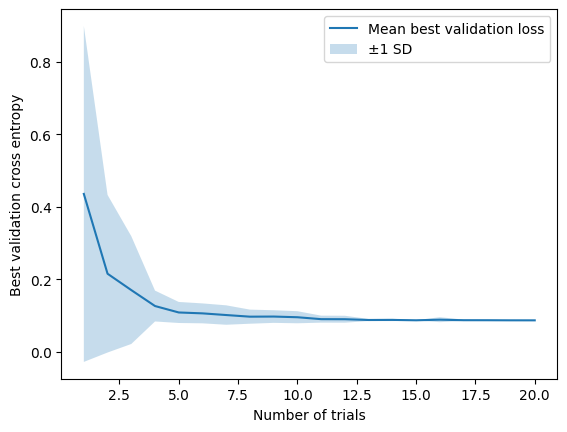

In [10]:
# Plot the effect of the number of trials.
# Repeated subsets of the 20 measured trials require no additional training.
# This describes this candidate pool, with sampling variability across subsets.
validation_losses = np.array([trial[1] for trial in trials])
rng = np.random.default_rng(SEED + 100)
budget = np.arange(1, 21)
sampled_best = np.empty((50, len(budget)))
for column, n_trials in enumerate(budget):
    for repeat in range(50):
        chosen = rng.choice(len(validation_losses), n_trials, replace=False)
        sampled_best[repeat, column] = validation_losses[chosen].min()

mean = sampled_best.mean(axis=0)
sd = sampled_best.std(axis=0, ddof=1)
plt.plot(budget, mean, label='Mean best validation loss')
plt.fill_between(budget, mean - sd, mean + sd, alpha=0.25, label='±1 SD')
plt.xlabel('Number of trials')
plt.ylabel('Best validation cross entropy')
plt.legend()
plt.show()
